# Chart 4: the waiting list and the survey on one time axis

**Alessandro**, Data Visualisation 4, The Foreigners Team

Question (Q3): did the hospital waiting list and the share of people who went without care because of waiting move the same way?

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PREPARED = Path("data/prepared")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

ORANGE = "#eb6834"  # waiting
BLUE = "#2a78d6"    # cost
GREY = "#898781"    # EU average and background

unmet = pd.read_csv(PREPARED / "unmet_need_by_reason_v1_2026-11-11.csv")
waiting = pd.read_csv(PREPARED / "waiting_list_national_v1_2026-11-11.csv", parse_dates=["snapshot"])

## Why this chart type?
The data is two different measures over 2019 to 2025: the yearly average waiting list (people) and the share of people who said waiting stopped them getting care (%). I chose two stacked line panels on one time axis. A dual-axis chart would let me pick axis ranges that make the two lines look tightly linked, which overstates the connection. A connected scatter would hide time and is hard to read with only 7 points.

## Step 1: yearly average of the waiting list
Add the bands for each monthly snapshot, then average by year. 2026 is left out because it only has nine months.

In [2]:
total = waiting.groupby("snapshot")["people"].sum() / 1000
yearly_list = total.groupby(total.index.year).mean().loc[2019:2025]
yearly_list.round(1)

snapshot
2019    555.6
2020    588.5
2021    636.0
2022    619.6
2023    592.2
2024    585.6
2025    602.1
Name: people, dtype: float64

## Step 2: the survey answer for Ireland

In [3]:
ie = unmet[(unmet["group"] == "Ireland") & (unmet["reason"] == "Waiting list")]
survey = ie.set_index("year")["pct"].loc[2019:2025]
survey

year
2019    1.0
2020    1.2
2021    2.0
2022    2.3
2023    2.1
2024    2.7
2025    2.1
Name: pct, dtype: float64

## Step 3: check the numbers against the guide

In [4]:
assert round(yearly_list[2019] * 1000) == 555628
assert round(yearly_list[2021] * 1000) == 636015
assert round(yearly_list[2024] * 1000) == 585630
assert round(yearly_list[2025] * 1000) == 602124
assert [survey[y] for y in (2019, 2021, 2024, 2025)] == [1.0, 2.0, 2.7, 2.1]
print("All checks passed")

All checks passed


## Step 4: how often did they move the same way?

In [5]:
same = (yearly_list.diff().dropna() > 0) == (survey.diff().dropna() > 0)
print(same.to_string())
print(f"Same direction in {same.sum()} of {len(same)} year changes")

snapshot
2020     True
2021     True
2022    False
2023     True
2024    False
2025    False
Same direction in 3 of 6 year changes


## Step 5: the chart

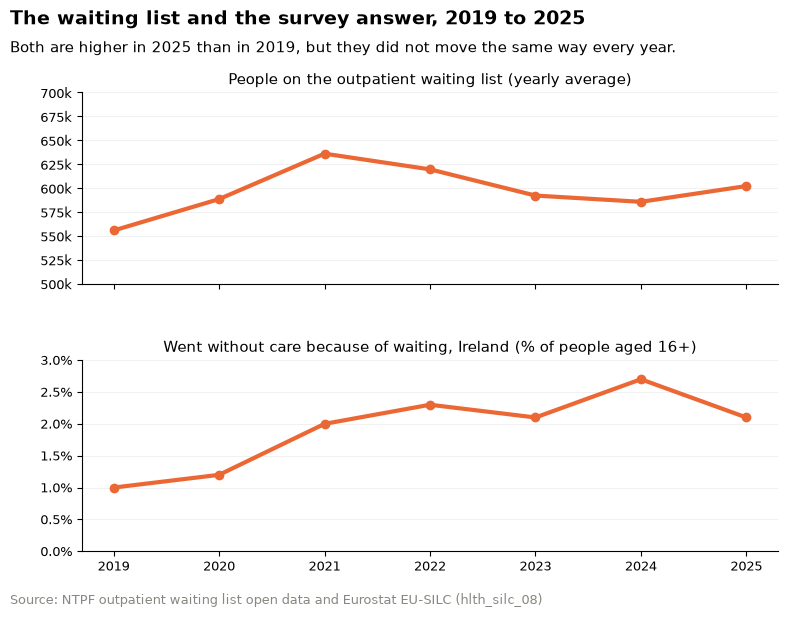

In [6]:
years = list(range(2019, 2026))

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(8, 6.2))  # two panels, one shared year axis

top.plot(years, yearly_list, color=ORANGE, marker="o", linewidth=3)
top.set_title("People on the outpatient waiting list (yearly average)", fontsize=11)
top.set_ylim(500, 700)
top.set_yticks(range(500, 701, 25))
top.set_yticklabels([f"{v}k" for v in range(500, 701, 25)])

bottom.plot(years, survey, color=ORANGE, marker="o", linewidth=3)
bottom.set_title("Went without care because of waiting, Ireland (% of people aged 16+)", fontsize=11)
bottom.set_ylim(0, 3)
bottom.set_yticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
bottom.yaxis.set_major_formatter(PercentFormatter(decimals=1))
bottom.set_xticks(years)

for ax in (top, bottom):
    ax.grid(axis="y", color="#efefef", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=9)

fig.text(
    0.01,
    0.95,
    "The waiting list and the survey answer, 2019 to 2025",
    fontsize=14,
    fontweight="bold",
    ha="left",
)
fig.text(
    0.01,
    0.905,
    "Both are higher in 2025 than in 2019, but they did not move the same way every year.",
    fontsize=10.5,
    ha="left",
)
fig.text(
    0.01,
    0.015,
    "Source: NTPF outpatient waiting list open data and Eurostat EU-SILC (hlth_silc_08)",
    fontsize=9,
    color=GREY,
    ha="left",
)
fig.subplots_adjust(top=0.84, bottom=0.1, left=0.1, right=0.97, hspace=0.4)
fig.savefig(FIGURES / "chart4_list_and_survey.png", dpi=200)
plt.show()

## Commentary

Over 2019 to 2025 both measures end higher than they started (list 556k to 602k, survey answer 1.0% to 2.1%). Year by year the link is weaker: the list peaked in 2021 and fell until 2024, while the survey answer kept rising to 2.7% in 2024. They moved the same way in 3 of 6 year changes. The chart shows direction, not cause, and the two are different measures.

Keep in mind:
- The list covers hospital outpatients only, and the survey covers all medical care.
- The top panel starts at 500k and not at zero, so the movement of the list can be seen.
- The 2021 average uses 11 snapshots, because June 2021 is missing.
- 2026 is left out because it has only nine months. Its average so far, about 666,000, is higher than 2021.
- Eurostat flags a break in Ireland's series in 2019 and 2020, so those two survey values are not fully comparable.

## Decisions
- Chart type: 
Two stacked line panels, one shared time axis. Rejected: dual axis (overstates the link) and connected scatter (hides time, only 7 points). My reason: The question is whether two different measures move the same way. Two panels let each one keep its own honest scale on a shared year axis, so the reader can compare direction without me choosing axis ranges that make the link look tighter. Bars would also have been wrong for the list, because from a zero baseline the change from 556k to 636k would look tiny.
- Title: 
"Moved the same way overall" is true because both end higher in 2025 than in 2019 (list 556k to 602k, survey 1.0% to 2.1%). "But not every year" is true because they matched in only 3 of 6 year changes, and from 2021 to 2024 the list fell while the survey answer rose from 2.0% to 2.7%. I kept it cautious because they are different measures and seven points can't show a cause.
- Annotated:
the 2021 list peak, the 2024 survey peak and are labelled because they fall in different years, and that mismatch is the main point of the chart. The hollow points mark 2019 and 2020 as survey break years, the same way as on the other charts, so the reader doesn't treat the jump from 2020 to 2021 as fully comparable.
- Left out:
For 2026 (nine months only) because 2026 only covers January to September, so its average isn't comparable to full years. I mention in the note that the 2026 average so far (about 666k) is higher than 2021, so leaving it out doesn't hide that.
- AI suggested / I decided: 
The AI set out four chart options with pros and cons (stacked panels, dual axis, connected scatter, indexed lines) and displayed pros and cons of each. From that I chose stacked panels and gave the reasons for rejecting the dual axis and the scatter. I then asked the AI to build the full chart and notebook as a draft for inspiration, and I plan to review it and edit it myself. The AI wrote the code and the annotation positions. I will decide the final title, annotations and wording.